In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, classification_report, ConfusionMatrixDisplay, make_scorer,
)

df = pd.read_csv("../data/wine_quality_cleaned.csv")
print(df.shape)

(3961, 12)


In [2]:
df["quality_category"] = np.where(df["quality"] >= 7, "Good", "Not Good")
display(df[["quality", "quality_category"]].head(10))

,quality,quality_category
0,6,Not Good
1,6,Not Good
2,6,Not Good
3,6,Not Good
4,6,Not Good
5,6,Not Good
6,5,Not Good
7,5,Not Good
8,5,Not Good
9,7,Good


,Count,Percentage
quality_category,,
Not Good,3136,79.17
Good,825,20.83


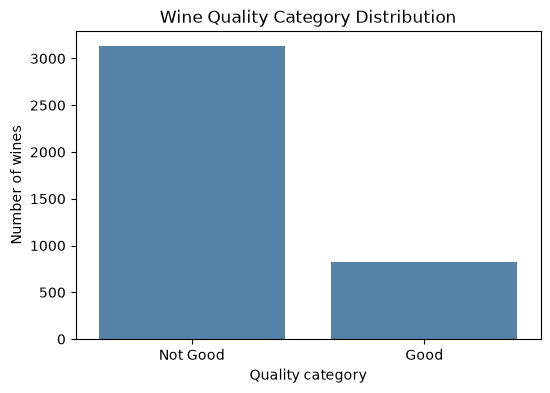

In [3]:
class_summary = pd.DataFrame({
    "Count": df["quality_category"].value_counts(),
    "Percentage": df["quality_category"].value_counts(normalize=True) * 100,
})
display(class_summary.round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="quality_category", order=["Not Good", "Good"], color="steelblue")
plt.title("Wine Quality Category Distribution")
plt.xlabel("Quality category")
plt.ylabel("Number of wines")
plt.savefig("../outputs/charts/quality_category_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

baseline = class_summary["Percentage"].max()


In [4]:
X_cls = df.drop(columns=["quality", "quality_category"])
y_cls = df["quality_category"]

print("Predictors (%d):" % X_cls.shape[1], X_cls.columns.tolist())
print("Target shape:", y_cls.shape)

Predictors (11): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Target shape: (3961,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

print("Training data:", X_train.shape, " | Testing data:", X_test.shape)
print()
print("Class % in training set:\n", (y_train.value_counts(normalize=True) * 100).round(2))
print("Class % in testing set:\n", (y_test.value_counts(normalize=True) * 100).round(2))

Training data: (3168, 11)  | Testing data: (793, 11)

Class % in training set:
 quality_category
Not Good    79.17
Good        20.83
Name: proportion, dtype: float64
Class % in testing set:
 quality_category
Not Good    79.19
Good        20.81
Name: proportion, dtype: float64


In [6]:
clf_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, model in clf_models.items():
    model.fit(X_train, y_train)

print("All three classification models trained successfully")

All three classification models trained successfully


In [7]:
y_test_binary = (y_test == "Good").astype(int)

def good_probability(model, X):
    return model.predict_proba(X)[:, list(model.classes_).index("Good")]

rows = []
clf_predictions = {}
for name, model in clf_models.items():
    pred = model.predict(X_test)
    clf_predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label="Good", zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label="Good", zero_division=0),
        "F1-Score": f1_score(y_test, pred, pos_label="Good", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_binary, good_probability(model, X_test)),
    })

clf_comparison = pd.DataFrame(rows)
display(clf_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8020,0.5417,0.3152,0.3985,0.7972
1,Decision Tree,0.7415,0.3864,0.4121,0.3988,0.6201
2,Random Forest,0.8235,0.6087,0.4242,0.5000,0.8295


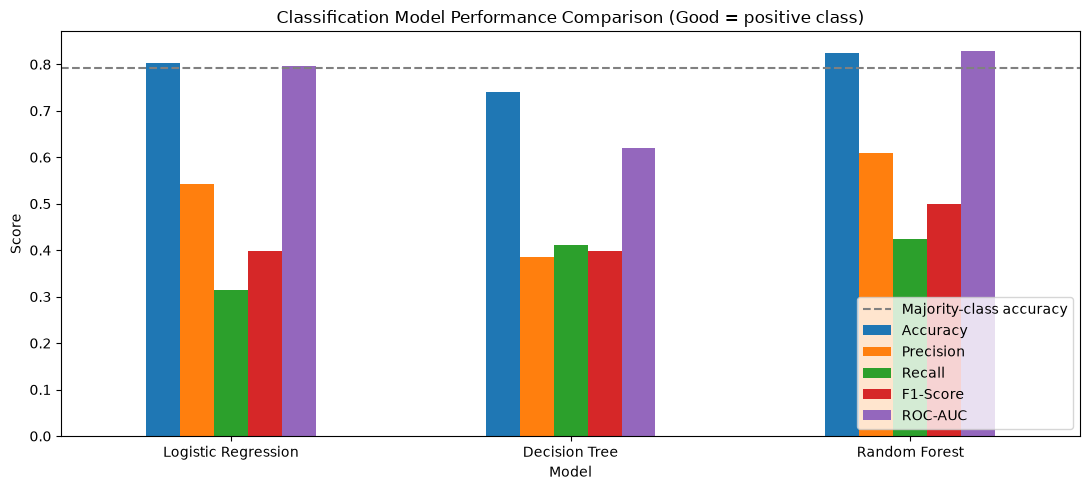

In [8]:
clf_comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.axhline(baseline / 100, color="gray", linestyle="--", label="Majority-class accuracy")
plt.title("Classification Model Performance Comparison (Good = positive class)")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/charts/classification_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Selected model (highest F1 for the Good class): Random Forest


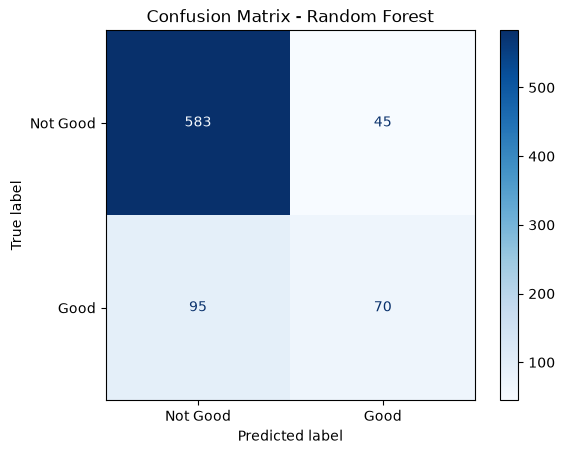

ROC-AUC Score: 0.8295

              precision    recall  f1-score   support

        Good       0.61      0.42      0.50       165
    Not Good       0.86      0.93      0.89       628

    accuracy                           0.82       793
   macro avg       0.73      0.68      0.70       793
weighted avg       0.81      0.82      0.81       793



In [9]:
best_model_name = clf_comparison.sort_values(by="F1-Score", ascending=False).iloc[0]["Model"]
best_model = clf_models[best_model_name]
best_pred = clf_predictions[best_model_name]
print("Selected model (highest F1 for the Good class):", best_model_name)

cm = confusion_matrix(y_test, best_pred, labels=["Not Good", "Good"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Good", "Good"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - " + best_model_name)
plt.savefig("../outputs/charts/confusion_matrix_best_model.png", dpi=150, bbox_inches="tight")
plt.show()

roc_auc = roc_auc_score(y_test_binary, good_probability(best_model, X_test))
print("ROC-AUC Score:", round(roc_auc, 4))
print()
print(classification_report(y_test, best_pred))

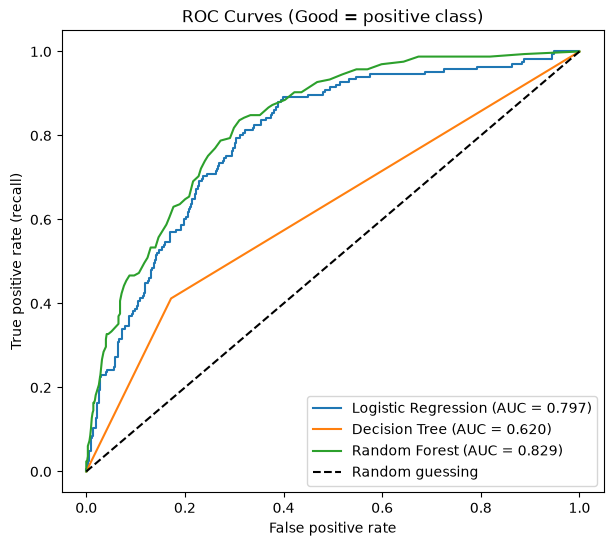

In [10]:
plt.figure(figsize=(7, 6))
for name, model in clf_models.items():
    fpr, tpr, _ = roc_curve(y_test_binary, good_probability(model, X_test))
    auc = roc_auc_score(y_test_binary, good_probability(model, X_test))
    plt.plot(fpr, tpr, label="%s (AUC = %.3f)" % (name, auc))
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC Curves (Good = positive class)")
plt.legend(loc="lower right")
plt.savefig("../outputs/charts/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

,Feature,Importance
10,alcohol,0.2387
7,density,0.1023
4,chlorides,0.0927
8,pH,0.0742
6,total sulfur dioxide,0.0569
5,free sulfur dioxide,0.0503
0,fixed acidity,0.0488
3,residual sugar,0.0430
1,volatile acidity,0.0426
9,sulphates,0.0388


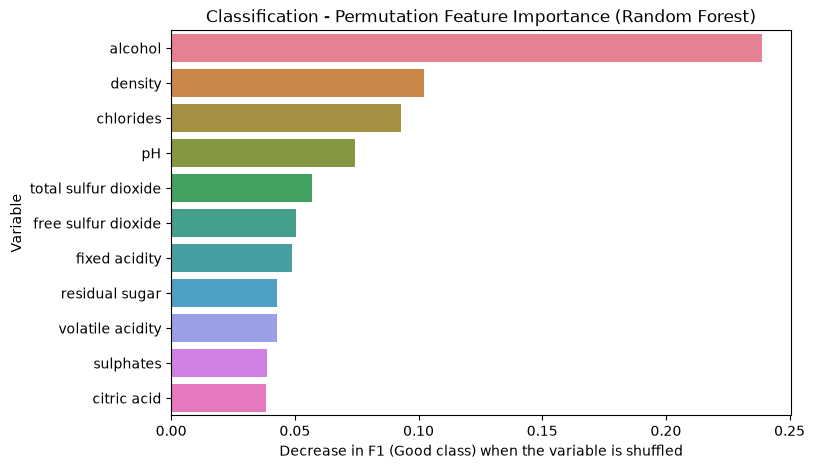

In [11]:
rf_clf = clf_models["Random Forest"]
good_f1 = make_scorer(f1_score, pos_label="Good")

perm = permutation_importance(
    rf_clf, X_test, y_test,
    n_repeats=10, random_state=42, scoring=good_f1,
)

cls_importance = pd.DataFrame({
    "Feature": X_cls.columns,
    "Importance": perm.importances_mean,
}).sort_values(by="Importance", ascending=False)

display(cls_importance.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=cls_importance, x="Importance", y="Feature", hue="Feature", legend=False)
plt.title("Classification - Permutation Feature Importance (Random Forest)")
plt.xlabel("Decrease in F1 (Good class) when the variable is shuffled")
plt.ylabel("Variable")
plt.savefig("../outputs/charts/classification_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
rows = []
for name, model in clf_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train F1": f1_score(y_train, train_pred, pos_label="Good", zero_division=0),
        "Test F1": f1_score(y_test, test_pred, pos_label="Good", zero_division=0),
    })

cls_overfit = pd.DataFrame(rows)
display(cls_overfit.round(4))

,Model,Train Accuracy,Test Accuracy,Train F1,Test F1
0,Logistic Regression,0.815,0.8020,0.4311,0.3985
1,Decision Tree,1.000,0.7415,1.0000,0.3988
2,Random Forest,1.000,0.8235,1.0000,0.5000


In [13]:
cls_out = clf_comparison.copy()
cls_out.insert(0, "Task", "Classification")

path = "../outputs/model_comparison.csv"
if os.path.exists(path):
    previous = pd.read_csv(path)
    previous = previous[previous["Task"] == "Regression"]
    combined = pd.concat([previous, cls_out], ignore_index=True)
else:
    combined = cls_out

combined.to_csv(path, index=False)
clf_comparison.to_csv("../outputs/classification_model_comparison.csv", index=False)
display(combined.round(4))

,Task,Model,MAE,MSE,RMSE,R2 Score,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regression,Linear Regression,0.6012,0.6051,0.7779,0.2621,NaN,NaN,NaN,NaN,NaN
1,Regression,Decision Tree,0.7478,1.1160,1.0564,-0.3608,NaN,NaN,NaN,NaN,NaN
2,Regression,Random Forest,0.5833,0.5811,0.7623,0.2914,NaN,NaN,NaN,NaN,NaN
3,Classification,Logistic Regression,NaN,NaN,NaN,NaN,0.8020,0.5417,0.3152,0.3985,0.7972
4,Classification,Decision Tree,NaN,NaN,NaN,NaN,0.7415,0.3864,0.4121,0.3988,0.6201
5,Classification,Random Forest,NaN,NaN,NaN,NaN,0.8235,0.6087,0.4242,0.5000,0.8295


 model comparison and recommendation


Regression:Random Forest: RMSE 0.762, R2 0.291 (Linear Regression close behind: 0.778 and 0.262) 
Classification:Random Forest:F1 0.50, ROC-AUC 0.83, accuracy 82.4% (baseline 79.2%) 

Recommendation: the Random Forest is the most suitable model for both prediction tasks in this project. For explaining why a wine scores higher or lower, use the OLS model without density (notebook 04) because it is interpretable and free of multicollinearity.

Most useful variables: alcohol (clearly first in both the regression and classification forests), then volatile acidity (regression) and density/chlorides (classification).

Limitations 
 All models overfit to some degree and explain a limited share of quality (regression R2 about 0.29); the chemical measurements alone do not determine a tasting score.
 Quality is a subjective, ordinal rating, and the classes are imbalanced (21% Good).- The data are white wines from one region (Vinho Verde, Portugal); results may not transfer to other wines.
 One random split was used, and no hyper-parameter tuning or cross-validation was done.
 Removing duplicates reduced the sample from 4,898 to 3,961 wines.

Future improvements: cross-validation and hyper-parameter tuning, class weights or threshold tuning to improve recall of Good wines, gradient boosting, robust or ordinal regression, and adding the red-wine data.